# Regression vs. flow: Gaussian statistical separation

**Finite-sample experiment.** 从上到下运行本 notebook，即可复现报告的结构化 Gaussian flow、几何对照和普通 neural-flow pilot。代码与本轮执行输出均已保留。

本实验研究**有限样本统计估计**，主横轴是独立 expert 样本数 $n$；不是 population GD 的更新数。先固定 observation，只学习一个二维常数动作。采用 professor 提供的 *Statistical Separation Report*，式 (1)–(9)、Theorem 1–2 和 Corollary 3：
$$Y_i\sim N(m,\Sigma_P),\quad m=\mu u,\quad P=uu^\top,\quad\Sigma_P=aP+b(I-P),\quad a>b>0.$$
$u$ 未知；主实验把它固定旋转 $0.6$ rad，学习函数没有接收真实 $u,P,m$。$a,b$ 在报告的主构造中已知；另报告同数据估计 spectrum 的控制。参考 clean manifold 是 $\mathcal M=\operatorname{range}(P)$，观测 Gaussian 因 $b>0$ 是满维的。

本节回答两个不同问题：
1. **报告复现：** 精确的结构化 FM empirical optimizer 是否有更低 normal risk？
2. **Neural pilot：** 不加入 mean–covariance alignment 的普通 MLP velocity 是否也出现这个收益？后者是实验问题，没有预设结论。

所有风险为**平方误差的平均值**。解析统计实验的误差带是跨独立训练数据集的 95% Monte Carlo interval；neural 部分使用 30 个独立数据集及配对 bootstrap。

依赖：`jax numpy matplotlib scipy pandas`，以及 Jupyter 自带的 IPython display。CPU 可以运行。

**本轮结果导航。** 报告的结构化 FM 分离成功复现；普通 MLP flow 在本轮固定预算下未复现该收益。最后的 readout 给出数值、区间及拟合精度限制。

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from jax.example_libraries import optimizers
from scipy.integrate import quad, solve_ivp
from scipy.optimize import minimize
from IPython.display import Markdown, display

jax.config.update('jax_enable_x64', True)
G_SEED = 20261016
G_A, G_B, G_MU, G_ANGLE = 100., 1., 1., 0.6
G_NS = np.array([32, 64, 128, 256, 512, 1024, 2048])
G_REPEATS = 100_000
G_NEURAL_DATASETS = 30
G_NEURAL_N = 512
G_NEURAL_WIDTH = 32
G_NEURAL_STEPS = 12_000
G_NEURAL_BATCH = 128
G_NEURAL_LRS = np.array([0.001, 0.003])
G_NEURAL_LOG = np.array([0, 100, 300, 1000, 3000, 6000, 12000])
assert G_A > G_B > 0 and G_REPEATS >= 1000 and G_NEURAL_DATASETS >= 2
assert G_NEURAL_LOG[-1] == G_NEURAL_STEPS
G_R = np.array([[np.cos(G_ANGLE), -np.sin(G_ANGLE)],
                [np.sin(G_ANGLE), np.cos(G_ANGLE)]])
G_U, G_Q = G_R[:, 0], G_R[:, 1]
G_P = np.outer(G_U, G_U)
G_TRUE_MEAN = G_MU * G_U
G_COLORS = {'Regression': '#D55E00', 'Structured FM': '#0072B2',
            'Geometry regression': '#009E73', 'Neural flow': '#8B5DA8'}
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.16,
    'figure.constrained_layout.use': True})
print(f'JAX {jax.__version__}; devices={jax.devices()}')
print(f'Exact statistical experiment: {G_REPEATS:,} independent datasets per point.')
print(f'Neural pilot: {G_NEURAL_DATASETS} datasets x {len(G_NEURAL_LRS)} learning rates; '
      f'{G_NEURAL_STEPS:,} updates, batch={G_NEURAL_BATCH}, width={G_NEURAL_WIDTH}.')

JAX 0.11.2; devices=[CpuDevice(id=0)]
Exact statistical experiment: 100,000 independent datasets per point.
Neural pilot: 30 datasets x 2 learning rates; 12,000 updates, batch=128, width=32.


## Exact learners and metrics

普通 regression 的全局最优解为 $\widehat m_R=\bar Y$。若 Gaussian flow 的 mean 与 covariance 独立拟合，其 zero-seed endpoint 也为 $\bar Y$。

报告的 flow 在每个时刻使用同一组 $m',P'$，并强制 $m'\in\operatorname{range}(P')$：
$$v(t,w)=m'+[t\Sigma_{P'}-(1-t)I][t^2\Sigma_{P'}+(1-t)^2I]^{-1}(w-tm').$$
用独立 $Z\sim N(0,I)$、$t\sim U(0,1)$ 最小化原始 CFM loss：
$$\widehat L=\frac1n\sum_i\int_0^1 E_Z\|v(t,tY_i+(1-t)Z)-(Y_i-Z)\|^2dt.$$
精确积分后，$\kappa=\sqrt a/(\sqrt a-\sqrt b)$，$\widehat P=P_{\rm top}(C+\kappa\bar Y\bar Y^\top)$，$\widehat m_F=\widehat P\bar Y$。使用相同 learned projector 的 regression **逐数据集与它完全相同**。

$$N=E[(q^\top(\widehat m-m))^2],\quad T=E[(u^\top(\widehat m-m))^2],\quad E_{\rm mean}=N+T.$$
独立 noisy test-target MSE 为 $R=a+b+N+T$。全部 deterministic 输出用 zero seed；随机 seed 的风险单独报告。

In [2]:
def g_fit(ybar, cov, a, b):
    # No true projector or true mean is an argument to this learner.
    kappa = np.asarray(np.sqrt(a) / (np.sqrt(a) - np.sqrt(b)))
    matrix = cov + kappa[..., None, None] * ybar[..., :, None] * ybar[..., None, :]
    uhat = np.linalg.eigh(matrix)[1][..., :, -1]
    phat = uhat[..., :, None] * uhat[..., None, :]
    return np.einsum('...ij,...j->...i', phat, ybar), phat


def g_sufficient(rng, n, repeats, a, b, mu, normal_offset=0.):
    # Exact Gaussian mean / Wishart centered-covariance law (denominator n).
    mean = np.column_stack([mu + np.sqrt(a/n) * rng.normal(size=repeats),
                            normal_offset + np.sqrt(b/n) * rng.normal(size=repeats)])
    chi = rng.chisquare(n - 1, repeats)
    z = rng.normal(size=repeats)
    cov = np.empty((repeats, 2, 2))
    cov[:, 0, 0] = a * chi / n
    cov[:, 0, 1] = cov[:, 1, 0] = np.sqrt(a*b) * np.sqrt(chi) * z / n
    cov[:, 1, 1] = b * (z*z + rng.chisquare(n - 2, repeats)) / n
    return mean @ G_R.T, G_R @ cov @ G_R.T


def g_risks(prediction, true_mean):
    error = prediction - true_mean
    return np.stack([(error @ G_Q)**2, (error @ G_U)**2], axis=-1)


def g_rho(a, b, mu):
    kappa = np.sqrt(a) / (np.sqrt(a) - np.sqrt(b))
    return mu**2 * (a + kappa*kappa*mu*mu) / (a-b+kappa*mu*mu)**2


def g_velocity(t, w, mean, phat, a, b):
    va, vb = a*t*t + (1-t)**2, b*t*t + (1-t)**2
    slope = (t*a-(1-t))/va * phat + (t*b-(1-t))/vb * (np.eye(2)-phat)
    return mean + (w-t*mean) @ slope.T


g_rng = np.random.default_rng(G_SEED)
g_rows = []
g_started = time.perf_counter()
for mu, variances in [(1., [1.5, 9., 100.]), (0., [9., 100.])]:
    for a in variances:
        for n in G_NS:
            ybar, cov = g_sufficient(g_rng, int(n), G_REPEATS, a, G_B, mu)
            fm, phat = g_fit(ybar, cov, a, G_B)
            true_mean = mu * G_U
            r, f = g_risks(ybar, true_mean), g_risks(fm, true_mean)
            # Exact conditional expectation over a fresh Gaussian generation seed.
            sample_normal = f[:, 0] + G_B + (a-G_B)*np.einsum('i,nij,j->n', G_Q, phat, G_Q)
            eigs = np.linalg.eigvalsh(cov)
            plug, _ = g_fit(ybar, cov, eigs[:, -1], np.maximum(eigs[:, 0], 1/n))
            p = g_risks(plug, true_mean)
            normal = n/G_B * f[:, 0]
            g_rows.append(dict(mu=mu, a=a, n=int(n),
                reg_norm=float(n/G_B*r[:, 0].mean()), flow_norm=float(normal.mean()),
                flow_ci=float(1.96*normal.std(ddof=1)/np.sqrt(G_REPEATS)),
                reg_tangent=float(r[:, 1].mean()), flow_tangent=float(f[:, 1].mean()),
                mean_mse_ratio=float(f.sum(1).mean()/r.sum(1).mean()),
                paired_mse_ratio=float((a+G_B+f.sum(1).mean())/(a+G_B+r.sum(1).mean())),
                sample_normal=float(sample_normal.mean()),
                plug_norm=float(n/G_B*p[:, 0].mean()),
                rho=g_rho(a, G_B, mu)))
g_results = pd.DataFrame(g_rows)
display(g_results.query('mu == 1 and n in [32, 128, 512]')
        [['a', 'n', 'reg_norm', 'flow_norm', 'flow_ci', 'plug_norm', 'mean_mse_ratio', 'paired_mse_ratio']]
        .round(6))
print(f'Exact estimators completed in {time.perf_counter()-g_started:.1f}s; no neural training in this table.')

Exact estimators completed in 4.4s; no neural training in this table.


,a,n,reg_norm,flow_norm,flow_ci,plug_norm,mean_mse_ratio,paired_mse_ratio
0,1.5,32,1.001968,0.895207,0.007952,0.882193,0.955793,0.998657
2,1.5,128,0.995042,0.879312,0.007737,0.873563,0.952906,0.999636
4,1.5,512,0.999495,0.881468,0.007712,0.879909,0.952834,0.999908
7,9.0,32,1.006498,0.155492,0.001894,0.156321,0.916044,0.997456
9,9.0,128,0.994797,0.131820,0.001328,0.131998,0.914224,0.999332
11,9.0,512,0.988853,0.126646,0.001158,0.126671,0.914466,0.999832
14,100.0,32,0.995345,0.040748,0.000679,0.040756,0.990586,0.999716
16,100.0,128,1.004708,0.017798,0.000276,0.017798,0.990242,0.999924
18,100.0,512,1.004547,0.011899,0.000143,0.011899,0.990121,0.999981


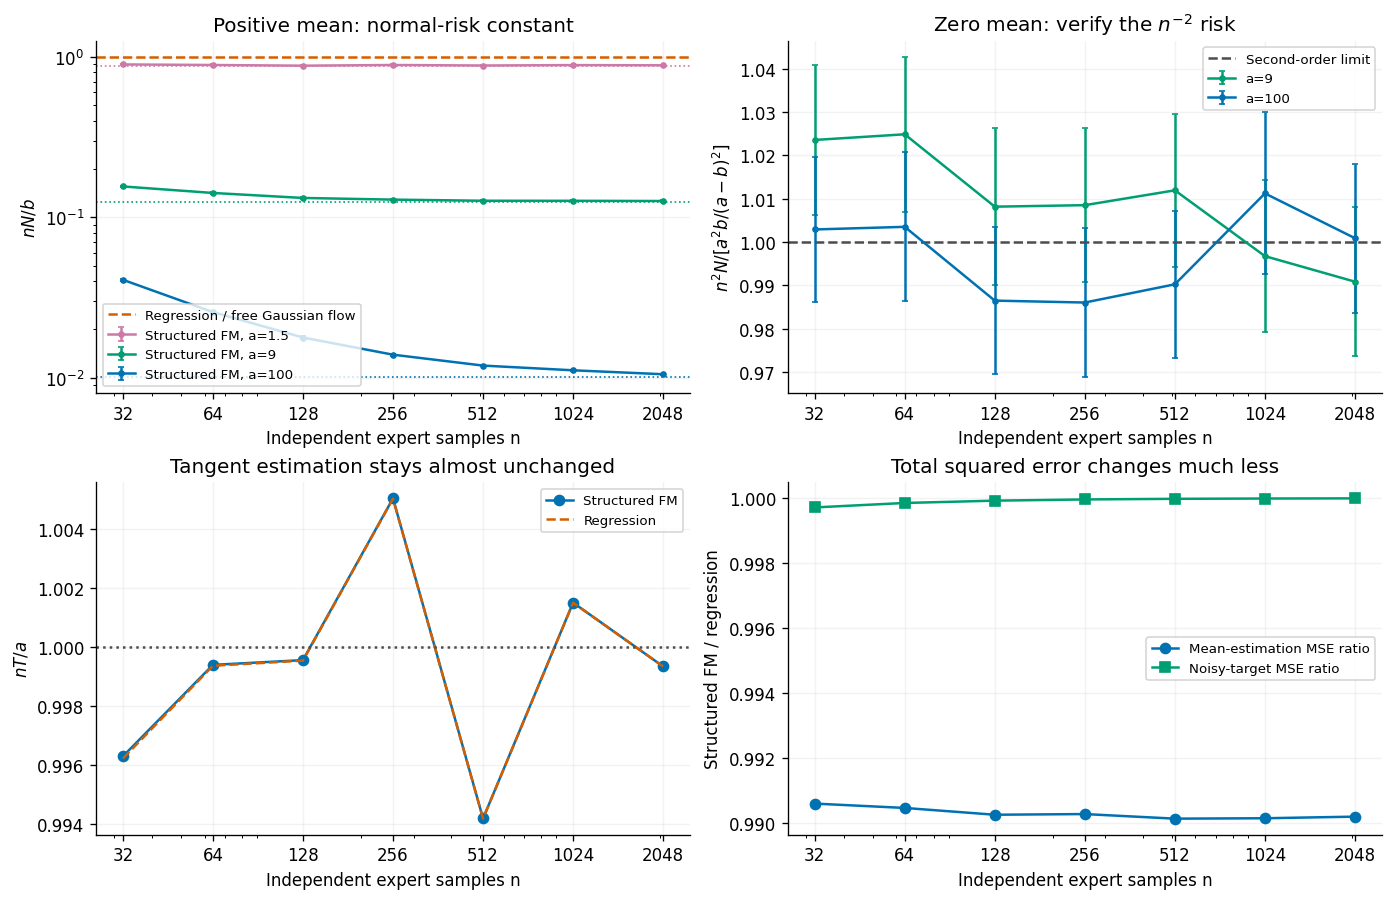

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.4))
for a, color in [(1.5, '#CC79A7'), (9., '#009E73'), (100., '#0072B2')]:
    frame = g_results.query('mu == 1 and a == @a')
    axes[0, 0].errorbar(frame.n, frame.flow_norm, yerr=frame.flow_ci, color=color,
                       marker='o', ms=3, capsize=2, label=f'Structured FM, a={a:g}')
    axes[0, 0].axhline(frame.rho.iloc[0], color=color, ls=':', lw=1)
axes[0, 0].axhline(1, color=G_COLORS['Regression'], ls='--', label='Regression / free Gaussian flow')
axes[0, 0].set(title='Positive mean: normal-risk constant', ylabel='$nN/b$', yscale='log')
for a, color in [(9., '#009E73'), (100., '#0072B2')]:
    frame = g_results.query('mu == 0 and a == @a')
    coefficient = a*a*G_B/(a-G_B)**2
    # Stored risk uses n*N/b; change normalization to n^2*N / coefficient.
    axes[0, 1].errorbar(frame.n, frame.flow_norm*G_B*frame.n/coefficient,
                    yerr=frame.flow_ci*G_B*frame.n/coefficient,
                    color=color, marker='o', ms=3, capsize=2, label=f'a={a:g}')
axes[0, 1].axhline(1, color='0.3', ls='--', label='Second-order limit')
axes[0, 1].set(title='Zero mean: verify the $n^{-2}$ risk', ylabel='$n^2N/[a^2b/(a-b)^2]$')
frame = g_results.query('mu == 1 and a == 100')
axes[1, 0].plot(frame.n, frame.flow_tangent*frame.n/100, marker='o', color='#0072B2', label='Structured FM')
axes[1, 0].plot(frame.n, frame.reg_tangent*frame.n/100, ls='--', color='#D55E00', label='Regression')
axes[1, 0].axhline(1, color='0.3', ls=':')
axes[1, 0].set(title='Tangent estimation stays almost unchanged', ylabel='$nT/a$')
axes[1, 1].plot(frame.n, frame.mean_mse_ratio, marker='o', color='#0072B2', label='Mean-estimation MSE ratio')
axes[1, 1].plot(frame.n, frame.paired_mse_ratio, marker='s', color='#009E73', label='Noisy-target MSE ratio')
axes[1, 1].set(title='Total squared error changes much less', ylabel='Structured FM / regression')
for ax in axes.flat:
    ax.set(xscale='log', xlabel='Independent expert samples n')
    ax.set_xticks(G_NS, labels=G_NS)
    ax.legend(fontsize=8)
plt.show()

## Geometry and seed choice, on one prespecified dataset

下面固定 seed 生成 $n=512$ 的真实原始数据，而非选择最有利的一组。左图展示 noisy observations；中图放大平均动作附近；右图比较同一 fitted flow 的 zero seed 与 fresh Gaussian seeds。真实 projector 只用于生成数据和评估。

在本模型中 $w_t=tm'+[t^2\Sigma_{P'}+(1-t)^2I]^{1/2}\xi$，zero seed 的路径恰为 $tm'$。随机 seed 的样本继续具有法向厚度，因此不能把 zero-seed theorem 当成 sampled-policy theorem。

Same learned-geometry regression equals structured FM: 1.1102230246251565e-16


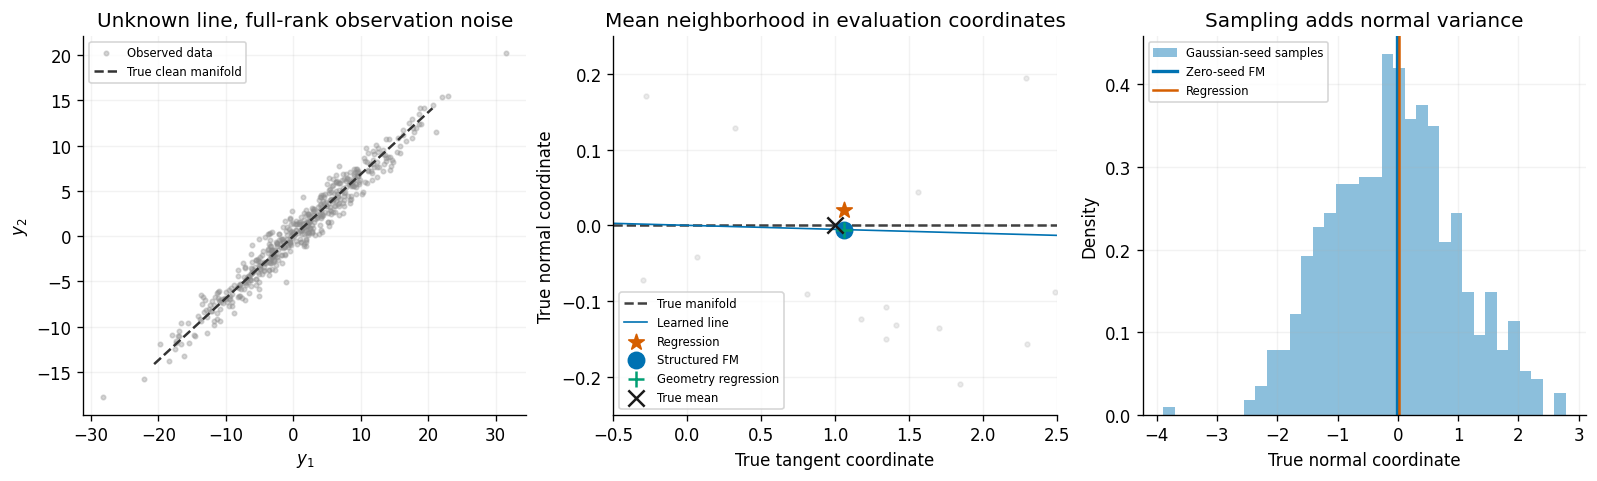

In [4]:
g_raw_rng = np.random.default_rng(G_SEED + 1)
g_data = (np.array([G_MU, 0.]) + g_raw_rng.normal(size=(512, 2))*np.sqrt([G_A, G_B])) @ G_R.T
g_bar = g_data.mean(0)
g_centered = g_data-g_bar
g_cov = g_centered.T @ g_centered/len(g_data)
g_fm, g_phat = g_fit(g_bar, g_cov, G_A, G_B)
g_geometry_reg = g_phat @ g_bar
g_seed = g_raw_rng.normal(size=(600, 2))
g_sqrt_cov = np.sqrt(G_A)*g_phat + np.sqrt(G_B)*(np.eye(2)-g_phat)
g_generated = g_fm + g_seed @ g_sqrt_cov.T
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.9))
s = np.linspace(-25, 25, 100)
axes[0].scatter(*g_data.T, color='0.55', s=7, alpha=.35, label='Observed data')
axes[0].plot(*(s[:, None]*G_U).T, color='0.2', ls='--', label='True clean manifold')
axes[0].set(title='Unknown line, full-rank observation noise', xlabel='$y_1$', ylabel='$y_2$')
g_plot_mean = np.array([g_bar, g_fm, g_geometry_reg, G_TRUE_MEAN]) @ G_R
local_data = g_data @ G_R
axes[1].scatter(*local_data.T, s=8, color='0.7', alpha=.25)
axes[1].axhline(0, color='0.25', ls='--', label='True manifold')
g_local_phat = G_R.T @ g_phat @ G_R
g_local_u = np.linalg.eigh(g_local_phat)[1][:, -1]
xx = np.linspace(-1, 3, 100)
axes[1].plot(xx, xx*g_local_u[1]/g_local_u[0], color='#0072B2', lw=1, label='Learned line')
for point, label, color, marker in zip(g_plot_mean,
        ['Regression', 'Structured FM', 'Geometry regression', 'True mean'],
        ['#D55E00', '#0072B2', '#009E73', '0.1'], ['*', 'o', '+', 'x']):
    axes[1].scatter(*point, color=color, marker=marker, s=95, zorder=5, label=label)
axes[1].set(xlim=(-.5, 2.5), ylim=(-.25, .25), title='Mean neighborhood in evaluation coordinates',
            xlabel='True tangent coordinate', ylabel='True normal coordinate')
axes[2].hist(g_generated @ G_Q, bins=35, density=True, color='#0072B2', alpha=.45, label='Gaussian-seed samples')
axes[2].axvline(g_fm @ G_Q, color='#0072B2', lw=2, label='Zero-seed FM')
axes[2].axvline(g_bar @ G_Q, color='#D55E00', label='Regression')
axes[2].set(title='Sampling adds normal variance', xlabel='True normal coordinate', ylabel='Density')
for ax in axes: ax.legend(fontsize=7)
plt.show()
print('Same learned-geometry regression equals structured FM:', np.max(np.abs(g_fm-g_geometry_reg)))

## Check the training objective, optimizer and ODE independently

设 $H_v=\pi/(4\sqrt v)$。积分后的完整 uniform FM loss 可写为
$$L=\frac\pi4\left[\operatorname{tr}\{\Sigma_{P'}^{-1/2}(C+(\bar Y-m')(\bar Y-m')^\top)\}+\operatorname{tr}(\Sigma_{P'}^{1/2})\right].$$
这来自原始 CFM 的噪声期望，没有用真实 velocity 作为训练标签。下面检查该式与逐时刻积分是否一致，并用仅接收样本统计量的多起点数值优化拟合 $(\theta,\mu')$。它验证实际 FM objective 的最优解，避免只实现一个 post-hoc projector 却称它为 FM。

In [5]:
def g_objective(params, ybar=g_bar, cov=g_cov):
    angle, length = params
    direction = np.array([np.cos(angle), np.sin(angle)])
    phat = np.outer(direction, direction)
    mean = length*direction
    scatter = cov + np.outer(ybar-mean, ybar-mean)
    invsqrt = phat/np.sqrt(G_A) + (np.eye(2)-phat)/np.sqrt(G_B)
    return np.pi/4*(np.trace(invsqrt @ scatter)+np.sqrt(G_A)+np.sqrt(G_B))


g_fits = [minimize(g_objective, [angle, 0.], method='BFGS',
                  options={'gtol': 1e-8, 'maxiter': 1000})
          for angle in np.linspace(0, np.pi, 8, endpoint=False)]
g_opt = min(g_fits, key=lambda fit: fit.fun)
g_numeric_mean = g_opt.x[1]*np.array([np.cos(g_opt.x[0]), np.sin(g_opt.x[0])])
g_hat_angle = np.arctan2(np.linalg.eigh(g_phat)[1][1, -1], np.linalg.eigh(g_phat)[1][0, -1])
g_closed_params = np.array([g_hat_angle, g_fm @ np.array([np.cos(g_hat_angle), np.sin(g_hat_angle)])])

def g_loss_at_time(t):
    va, vb = G_A*t*t+(1-t)**2, G_B*t*t+(1-t)**2
    alpha = (1-t)/va*g_phat+(1-t)/vb*(np.eye(2)-g_phat)
    beta = t*G_A/va*g_phat+t*G_B/vb*(np.eye(2)-g_phat)
    scatter = g_cov+np.outer(g_bar-g_fm, g_bar-g_fm)
    return np.trace(alpha @ scatter @ alpha.T)+np.sum(beta*beta)


g_integral = quad(g_loss_at_time, 0, 1, epsabs=1e-10)[0]
g_ode = solve_ivp(lambda t, w: g_velocity(t, w, g_fm, g_phat, G_A, G_B),
                  (0, 1), g_seed[0], rtol=1e-10, atol=1e-11)
g_endpoint = g_fm+g_sqrt_cov @ g_seed[0]
np.testing.assert_allclose(g_integral, g_objective(g_closed_params), rtol=1e-10)
np.testing.assert_allclose(g_numeric_mean, g_fm, atol=3e-6)
np.testing.assert_allclose(g_ode.y[:, -1], g_endpoint, atol=2e-8)
np.testing.assert_allclose(g_geometry_reg, g_fm, atol=1e-13)
assert np.max(np.abs(g_results.reg_norm-1)) < .025
assert g_results.query('mu == 1 and a == 100 and n == 512').flow_norm.iloc[0] < .08
print(f'Original integrated CFM loss: {g_integral:.10f}; reduced objective: {g_objective(g_closed_params):.10f}')
print(f'Numerical optimizer / closed-form endpoint gap: {np.linalg.norm(g_numeric_mean-g_fm):.3g}')
print(f'ODE / exact Gaussian endpoint gap: {np.linalg.norm(g_ode.y[:, -1]-g_endpoint):.3g}')
print('Checks of the estimator, independent time integral, ODE and statistical baseline passed.')

Original integrated CFM loss: 17.4878657903; reduced objective: 17.4878657903
Numerical optimizer / closed-form endpoint gap: 1.58e-07
ODE / exact Gaussian endpoint gap: 6.39e-11
Checks of the estimator, independent time integral, ODE and statistical baseline passed.


## Mechanism control: a free unknown normal offset

现在只增加 normal offset $\delta=0.3$：$m=\mu u+\delta q$，clean manifold 改为 $\delta q+\operatorname{range}(P)$。如果仍强制 mean 位于经过原点的 learned 主轴，模型已经 misspecified。下图使用相对**新的真实 affine manifold**的误差，检查 bias 是否会抵消收益。该控制违反主定理的 mean–covariance alignment 假设，不是主定理的反例。允许 mean 自由的 Gaussian flow / regression 都输出 $\bar Y$。

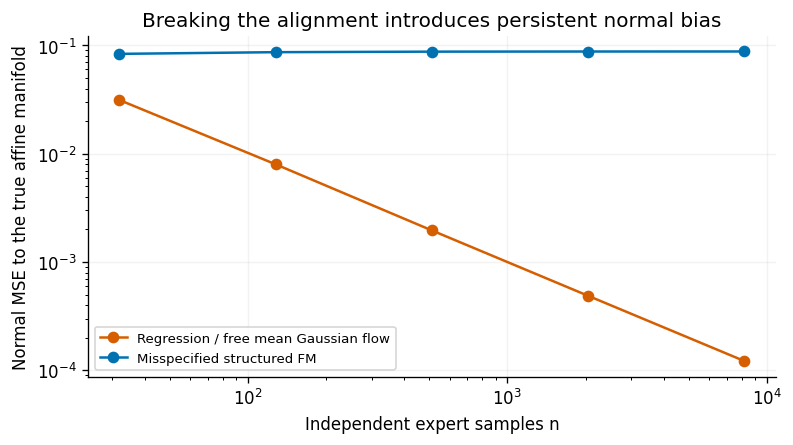

In [6]:
g_break_rows = []
for n in [32, 128, 512, 2048, 8192]:
    ybar, cov = g_sufficient(np.random.default_rng(G_SEED+int(n)), n, 30_000,
                            G_A, G_B, G_MU, normal_offset=.3)
    pred, _ = g_fit(ybar, cov, G_A, G_B)
    true_mean = G_MU*G_U+.3*G_Q
    g_break_rows.append((n, g_risks(ybar, true_mean)[:, 0].mean(),
                         g_risks(pred, true_mean)[:, 0].mean()))
g_break = np.array(g_break_rows)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.loglog(g_break[:, 0], g_break[:, 1], 'o-', color='#D55E00', label='Regression / free mean Gaussian flow')
ax.loglog(g_break[:, 0], g_break[:, 2], 'o-', color='#0072B2', label='Misspecified structured FM')
ax.set(title='Breaking the alignment introduces persistent normal bias',
       xlabel='Independent expert samples n', ylabel='Normal MSE to the true affine manifold')
ax.legend(fontsize=8)
plt.show()

## Unrestricted neural velocity pilot: same finite-data distribution

本节**重新训练普通 MLP velocity** $v_\theta(w,t)$，没有 $P$、rank constraint、终点投影或 analytic velocity skip connection。结构为 3–32–32–2，两个 tanh hidden layers；最后一层零初始化。没有 observation 输入，因为这里固定了同一个 observation。

30 组独立 expert datasets，每组 $n=512$。同一数据集在两个预先指定的 Adam 学习率 $0.001,0.003$ 下使用相同初始化和随机 source/time/index 序列；每个模型固定 12,000 步，batch 128。每次只从该组的 **512 个已观测 expert labels** 中有放回抽样；fresh source noise 和 time 不是新增 expert 数据。最终 checkpoint 作为主结果，不按 test adherence 挑模型。

输入 action 和输出 velocity 以该数据集的一个 scalar RMS scale 同时缩放，$Z\sim N(0,I)$ 仍在原始坐标生成。这只把每个数据集的原始 CFM loss 乘以一个正常数，不改变其 minimizer；缩放没有使用真实方向。主指标是 zero-seed ODE endpoint 的 normal MSE，另报告 fresh Gaussian seeds。作为固定 observation 的正确 regression optimum，baseline 直接使用精确 $\bar Y$，排除 regression 的优化误差。

这是有限预算的 neural pilot，不是报告定理的验证对象。表格和学习曲线用于辨别它是否接近 structured estimator；若不接近，可能涉及 optimization、finite-data mixture fitting 或缺少结构约束。

In [7]:
g_nn_rng = np.random.default_rng(G_SEED+100)
g_nn_data = (np.array([G_MU, 0.]) + g_nn_rng.normal(size=(G_NEURAL_DATASETS, G_NEURAL_N, 2))
             * np.sqrt([G_A, G_B])) @ G_R.T
g_nn_bar = g_nn_data.mean(1)
g_nn_center = g_nn_data-g_nn_bar[:, None]
g_nn_cov = np.einsum('rni,rnj->rij', g_nn_center, g_nn_center)/G_NEURAL_N
g_nn_exact, _ = g_fit(g_nn_bar, g_nn_cov, G_A, G_B)
g_nn_scale = np.maximum(np.sqrt(np.mean(g_nn_data**2, axis=(1, 2))), 1.)
g_nn_all_data = jnp.asarray(np.tile(g_nn_data, (len(G_NEURAL_LRS), 1, 1)), dtype=jnp.float32)
g_nn_all_scale = jnp.asarray(np.tile(g_nn_scale, len(G_NEURAL_LRS)), dtype=jnp.float32)
g_nn_all_lr = jnp.asarray(np.repeat(G_NEURAL_LRS, G_NEURAL_DATASETS), dtype=jnp.float32)
g_nn_keys = jax.random.split(jax.random.key(G_SEED+101), G_NEURAL_DATASETS)
g_nn_all_keys = jnp.concatenate([g_nn_keys]*len(G_NEURAL_LRS))

def g_nn_init(key):
    widths = [3, G_NEURAL_WIDTH, G_NEURAL_WIDTH, 2]
    keys = jax.random.split(key, 3)
    return tuple((jax.random.normal(k, (left, right), dtype=jnp.float32)*jnp.float32(np.sqrt(2/(left+right)))
                  if layer < 2 else jnp.zeros((left, right), dtype=jnp.float32),
                  jnp.zeros(right, dtype=jnp.float32))
                 for layer, (k, left, right) in enumerate(zip(keys, widths[:-1], widths[1:])))


def g_nn_velocity(params, w, t, scale):
    h = jnp.concatenate([w/scale, (2*jnp.broadcast_to(t, w.shape[:-1])-1)[..., None]], axis=-1)
    for weights, bias in params[:-1]:
        h = jnp.tanh(h @ weights + bias)
    return scale*(h @ params[-1][0]+params[-1][1])


def g_nn_loss(params, data, scale, key):
    ki, kz, kt = jax.random.split(key, 3)
    y = data[jax.random.randint(ki, (G_NEURAL_BATCH,), 0, data.shape[0])]
    z = jax.random.normal(kz, y.shape, dtype=jnp.float32)
    t = jax.random.uniform(kt, (G_NEURAL_BATCH,), dtype=jnp.float32)
    w = t[:, None]*y+(1-t[:, None])*z
    residual = (g_nn_velocity(params, w, t, scale)-(y-z))/scale
    return .5*jnp.mean(jnp.sum(residual**2, axis=-1))


g_nn_opt_init, _, g_nn_get = optimizers.adam(1.)
g_nn_initial = jax.vmap(g_nn_init)(g_nn_all_keys)
assert all(leaf.dtype == jnp.float32 for leaf in jax.tree.leaves(g_nn_initial))
g_nn_state = jax.vmap(g_nn_opt_init)(g_nn_initial)

def g_nn_one_update(i, state, data, scale, key, learning_rate):
    params = g_nn_get(state)
    key = jax.random.fold_in(key, i)
    gradient = jax.grad(g_nn_loss)(params, data, scale, key)
    return optimizers.adam(learning_rate)[1](i, gradient, state)


@jax.jit
def g_nn_advance(state, start, stop):
    def step(i, state):
        return jax.vmap(g_nn_one_update, in_axes=(None, 0, 0, 0, 0, 0))(
            i, state, g_nn_all_data, g_nn_all_scale, g_nn_all_keys, g_nn_all_lr)
    return jax.lax.fori_loop(start, stop, step, state)


g_nn_histories = [g_nn_initial]
g_nn_started = time.perf_counter()
g_nn_cursor = 0
for stop in G_NEURAL_LOG[1:]:
    while g_nn_cursor < stop:
        next_step = min(g_nn_cursor+1000, int(stop))
        g_nn_state = g_nn_advance(g_nn_state, g_nn_cursor, next_step)
        jax.block_until_ready(g_nn_state)
        g_nn_cursor = next_step
        print(f'Neural pilot: {g_nn_cursor:>6,}/{G_NEURAL_STEPS:,} updates; '
              f'{time.perf_counter()-g_nn_started:.1f}s elapsed', flush=True)
    g_nn_histories.append(jax.vmap(g_nn_get)(g_nn_state))
g_nn_history = jax.tree.map(lambda *items: jnp.stack(items), *g_nn_histories)
g_nn_final = g_nn_histories[-1]
print(f'Trained {len(g_nn_all_lr)} neural velocity fields; expert data were never refreshed.')

Neural pilot:    100/12,000 updates; 1.0s elapsed
Neural pilot:    300/12,000 updates; 1.5s elapsed
Neural pilot:  1,000/12,000 updates; 3.2s elapsed
Neural pilot:  2,000/12,000 updates; 5.5s elapsed
Neural pilot:  3,000/12,000 updates; 7.8s elapsed
Neural pilot:  4,000/12,000 updates; 10.0s elapsed
Neural pilot:  5,000/12,000 updates; 12.2s elapsed
Neural pilot:  6,000/12,000 updates; 14.3s elapsed
Neural pilot:  7,000/12,000 updates; 16.5s elapsed
Neural pilot:  8,000/12,000 updates; 18.7s elapsed
Neural pilot:  9,000/12,000 updates; 20.9s elapsed
Neural pilot: 10,000/12,000 updates; 23.1s elapsed
Neural pilot: 11,000/12,000 updates; 25.3s elapsed
Neural pilot: 12,000/12,000 updates; 27.9s elapsed
Trained 60 neural velocity fields; expert data were never refreshed.


RK4 128 -> 256: max zero-seed coordinate change 1.43e-06
Independent original-CFM validation objective, final (lr order): [17.644554 17.478834]
Free affine FM empirical optimum, averaged across the same datasets: 17.317928094146865


,model,normal_MSE,tangent_MSE,mean_MSE,normal_ratio,ratio_CI_low,ratio_CI_high
0,Regression = free Gaussian FM,0.001832,0.213089,0.214921,1.000000,1.000000,1.000000
1,Structured FM = geometry regression,0.000035,0.213101,0.213136,0.019375,0.010065,0.048149
2,"Neural FM zero seed, lr=0.001",0.013268,1.139809,1.153077,7.242450,5.089897,12.292340
3,"Neural FM sampled, lr=0.001",1.027719,106.765077,107.792796,560.984346,316.277077,1308.402237
4,"Neural FM zero seed, lr=0.003",0.023965,1.425171,1.449136,13.081168,6.576454,30.289814
5,"Neural FM sampled, lr=0.003",1.043911,104.353520,105.397431,569.822748,318.386067,1332.941356


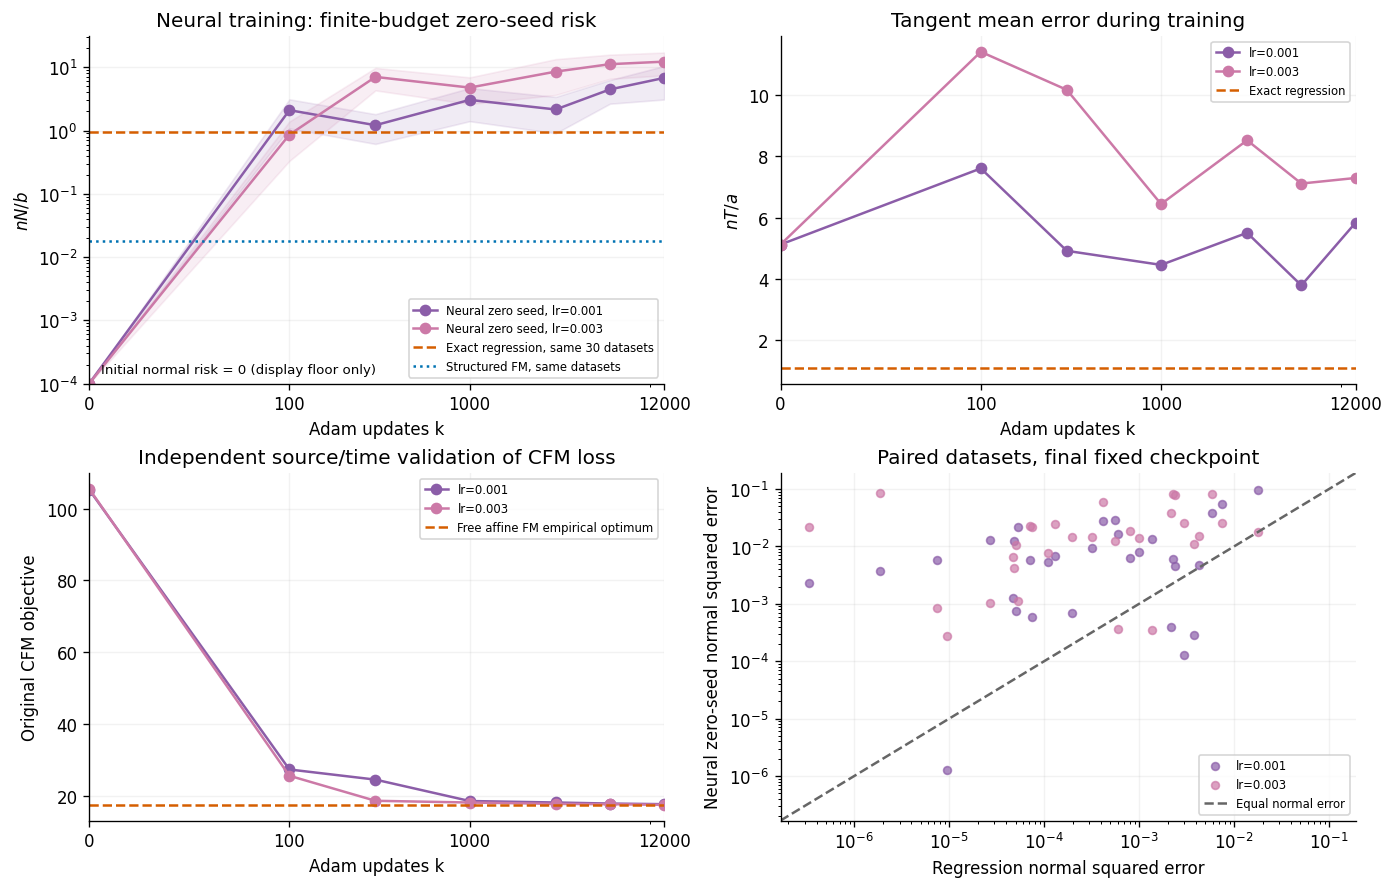

In [8]:
def g_nn_integrate_one(params, scale, seeds, steps):
    dt = jnp.asarray(1./steps, dtype=seeds.dtype)
    def step(i, w):
        t = jnp.asarray(i, dtype=seeds.dtype)*dt
        k1 = g_nn_velocity(params, w, t, scale)
        k2 = g_nn_velocity(params, w+dt*k1/2, t+dt/2, scale)
        k3 = g_nn_velocity(params, w+dt*k2/2, t+dt/2, scale)
        k4 = g_nn_velocity(params, w+dt*k3, t+dt, scale)
        return w+dt*(k1+2*k2+2*k3+k4)/6
    return jax.lax.fori_loop(0, steps, step, seeds)


def g_nn_integrate(params, seeds, steps=128):
    return jax.vmap(lambda p, s, z: g_nn_integrate_one(p, s, z, steps))(
        params, g_nn_all_scale, seeds)


g_nn_zero_seeds = jnp.zeros((len(g_nn_all_lr), 1, 2), dtype=jnp.float32)
g_nn_zero_history = np.asarray(jax.jit(jax.vmap(lambda p: g_nn_integrate(p, g_nn_zero_seeds)))(g_nn_history))[:, :, 0]
g_nn_zero = g_nn_zero_history[-1]
g_nn_refined = np.asarray(jax.jit(lambda p: g_nn_integrate(p, g_nn_zero_seeds, 256))(g_nn_final))[:, 0]
g_nn_ode_change = np.max(np.abs(g_nn_zero-g_nn_refined))
g_nn_sample_seeds = np.tile(g_nn_rng.normal(size=(G_NEURAL_DATASETS, 256, 2)), (len(G_NEURAL_LRS), 1, 1))
g_nn_samples = np.asarray(jax.jit(lambda p, z: g_nn_integrate(p, z, 128))(
    g_nn_final, jnp.asarray(g_nn_sample_seeds, dtype=jnp.float32)))
g_nn_zero_risks = g_risks(g_nn_zero, G_TRUE_MEAN).reshape(len(G_NEURAL_LRS), G_NEURAL_DATASETS, 2)
g_nn_sample_risks = g_risks(g_nn_samples, G_TRUE_MEAN).mean(1).reshape(len(G_NEURAL_LRS), G_NEURAL_DATASETS, 2)
g_nn_reg_risks = g_risks(g_nn_bar, G_TRUE_MEAN)
g_nn_exact_risks = g_risks(g_nn_exact, G_TRUE_MEAN)

# Fixed independent auxiliary draws check the original empirical CFM objective.
# No fresh expert labels are used; validation draws reuse the observed data.
g_nn_val_keys = jax.random.split(jax.random.key(G_SEED+104), len(g_nn_all_lr))
def g_nn_validation_one(params, data, scale, key):
    losses = jax.vmap(lambda k: g_nn_loss(params, data, scale, k))(jax.random.split(key, 32))
    return 2*scale*scale*losses.mean()  # Undo the training normalization and 1/2.
g_nn_validation = np.asarray(jax.jit(jax.vmap(lambda p: jax.vmap(g_nn_validation_one)(
    p, g_nn_all_data, g_nn_all_scale, g_nn_val_keys)))(g_nn_history))
g_nn_affine_loss = np.pi/2*np.sqrt(np.linalg.eigvalsh(g_nn_cov)).sum(-1).mean()

# Dataset-level paired bootstrap, not an interval over auxiliary seed draws.
g_boot = np.random.default_rng(G_SEED+102).integers(0, G_NEURAL_DATASETS, (20_000, G_NEURAL_DATASETS))
def g_nn_summary(name, risks):
    normal = risks[:, 0]
    ratio_boot = normal[g_boot].mean(1)/g_nn_reg_risks[g_boot, 0].mean(1)
    lo, hi = np.quantile(ratio_boot, [.025, .975])
    return dict(model=name, normal_MSE=normal.mean(), tangent_MSE=risks[:, 1].mean(),
                mean_MSE=risks.sum(1).mean(), normal_ratio=normal.mean()/g_nn_reg_risks[:, 0].mean(),
                ratio_CI_low=lo, ratio_CI_high=hi)


g_nn_summary_rows = [g_nn_summary('Regression = free Gaussian FM', g_nn_reg_risks),
                     g_nn_summary('Structured FM = geometry regression', g_nn_exact_risks)]
for i, lr in enumerate(G_NEURAL_LRS):
    g_nn_summary_rows.append(g_nn_summary(f'Neural FM zero seed, lr={lr:g}', g_nn_zero_risks[i]))
    g_nn_summary_rows.append(g_nn_summary(f'Neural FM sampled, lr={lr:g}', g_nn_sample_risks[i]))
g_nn_summary_table = pd.DataFrame(g_nn_summary_rows)
display(g_nn_summary_table.round(6))
print(f'RK4 128 -> 256: max zero-seed coordinate change {g_nn_ode_change:.3g}')
print('Independent original-CFM validation objective, final (lr order):',
      g_nn_validation[-1].reshape(len(G_NEURAL_LRS), G_NEURAL_DATASETS).mean(1))
print('Free affine FM empirical optimum, averaged across the same datasets:', g_nn_affine_loss)
assert g_nn_ode_change < 3e-4, 'Increase RK4 steps before interpreting neural results.'
assert np.isfinite(g_nn_zero_risks).all() and np.isfinite(g_nn_sample_risks).all()

g_nn_normal_history = ((g_nn_zero_history-G_TRUE_MEAN) @ G_Q)**2
g_nn_normal_history = g_nn_normal_history.reshape(len(G_NEURAL_LOG), len(G_NEURAL_LRS), G_NEURAL_DATASETS)
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.3))
axes = axes.ravel()
for i, (lr, color) in enumerate(zip(G_NEURAL_LRS, ['#8B5DA8', '#CC79A7'])):
    values = g_nn_normal_history[:, i]*G_NEURAL_N/G_B
    average = values.mean(1)
    halfwidth = 1.96*values.std(1, ddof=1)/np.sqrt(G_NEURAL_DATASETS)
    # Display floor only: the zero-velocity initial endpoint has zero normal risk.
    axes[0].plot(G_NEURAL_LOG, np.maximum(average, 1e-4), 'o-', color=color, label=f'Neural zero seed, lr={lr:g}')
    axes[0].fill_between(G_NEURAL_LOG, np.maximum(average-halfwidth, 1e-4),
                        np.maximum(average+halfwidth, 1e-4), color=color, alpha=.12)
    tangent = (((g_nn_zero_history-G_TRUE_MEAN) @ G_U)**2).reshape(
        len(G_NEURAL_LOG), len(G_NEURAL_LRS), G_NEURAL_DATASETS)[:, i].mean(1)
    axes[1].plot(G_NEURAL_LOG, tangent*G_NEURAL_N/G_A, 'o-', color=color, label=f'lr={lr:g}')
    own_loss = g_nn_validation.reshape(len(G_NEURAL_LOG), len(G_NEURAL_LRS), G_NEURAL_DATASETS)[:, i].mean(1)
    axes[2].plot(G_NEURAL_LOG, own_loss, 'o-', color=color, label=f'lr={lr:g}')
    axes[3].scatter(g_nn_reg_risks[:, 0], g_nn_zero_risks[i, :, 0], color=color, s=22,
                    alpha=.7, label=f'lr={lr:g}')
axes[0].axhline(g_nn_reg_risks[:, 0].mean()*G_NEURAL_N/G_B, color='#D55E00', ls='--', label='Exact regression, same 30 datasets')
axes[0].axhline(g_nn_exact_risks[:, 0].mean()*G_NEURAL_N/G_B, color='#0072B2', ls=':', label='Structured FM, same datasets')
axes[0].set(title='Neural training: finite-budget zero-seed risk', xlabel='Adam updates k',
            ylabel='$nN/b$', xscale='symlog', yscale='log')
positive = np.r_[g_nn_reg_risks[:, 0], g_nn_zero_risks[:, :, 0].ravel()]
limits = [max(positive.min()/2, 1e-12), positive.max()*2]
axes[1].axhline(g_nn_reg_risks[:, 1].mean()*G_NEURAL_N/G_A, color='#D55E00', ls='--', label='Exact regression')
axes[1].set(title='Tangent mean error during training', xlabel='Adam updates k',
            ylabel='$nT/a$', xscale='symlog')
axes[2].axhline(g_nn_affine_loss, color='#D55E00', ls='--', label='Free affine FM empirical optimum')
axes[2].set(title='Independent source/time validation of CFM loss', xlabel='Adam updates k',
            ylabel='Original CFM objective', xscale='symlog')
axes[3].plot(limits, limits, color='0.4', ls='--', label='Equal normal error')
axes[3].set(title='Paired datasets, final fixed checkpoint', xlabel='Regression normal squared error',
            ylabel='Neural zero-seed normal squared error', xscale='log', yscale='log', xlim=limits, ylim=limits)
axes[0].set_ylim(bottom=1e-4)
axes[0].text(.02, .03, 'Initial normal risk = 0 (display floor only)', transform=axes[0].transAxes, fontsize=8)
for ax in axes[:3]:
    ax.set_xscale('symlog', linthresh=100)
    ax.set_xlim(0, G_NEURAL_STEPS)
    ax.set_xticks([0, 100, 1000, G_NEURAL_STEPS], labels=['0', '100', '1000', str(G_NEURAL_STEPS)])
for ax in axes: ax.legend(fontsize=7)
plt.show()

## Independent checks and automatically generated research readout

下面直接从保存的数组生成结果描述，不预设 neural flow 赢。报告主定理与 neural pilot 的范围不同。

In [9]:
# Check original stochastic CFM targets on an independent source/time sample.
g_check_rng = np.random.default_rng(G_SEED+103)
g_check_n = 200_000
g_check_y = g_data[g_check_rng.integers(0, len(g_data), g_check_n)]
g_check_z = g_check_rng.normal(size=(g_check_n, 2))
g_check_t = g_check_rng.uniform(size=g_check_n)
g_check_w = g_check_t[:, None]*g_check_y+(1-g_check_t[:, None])*g_check_z
g_check_va = G_A*g_check_t**2+(1-g_check_t)**2
g_check_vb = G_B*g_check_t**2+(1-g_check_t)**2
g_check_slope = (((G_A*g_check_t-(1-g_check_t))/g_check_va)[:, None, None]*g_phat
    + ((G_B*g_check_t-(1-g_check_t))/g_check_vb)[:, None, None]*(np.eye(2)-g_phat))
g_check_v = g_fm+np.einsum('nij,nj->ni', g_check_slope, g_check_w-g_check_t[:, None]*g_fm)
g_check_squared = np.sum((g_check_v-(g_check_y-g_check_z))**2, axis=1)
g_check_se = g_check_squared.std(ddof=1)/np.sqrt(g_check_n)
assert abs(g_check_squared.mean()-g_integral) < 6*g_check_se
print(f'Independent original-CFM MC: {g_check_squared.mean():.6f} ± MC SE {g_check_se:.6f}; exact {g_integral:.6f}')

g_main = g_results.query('mu == 1 and a == 100 and n == 512').iloc[0]
g_text = (f'**报告复现。** a=100, b=1, μ=1, n=512 时，100,000 组独立数据集得到 '
          f'normal risk / (b/n) = **{g_main.flow_norm:.5f} ± {g_main.flow_ci:.5f}** '
          f'（95% MC interval 半宽）；理论渐近常数 {g_main.rho:.6f}。'
          f'均值估计 MSE 比为 {g_main.mean_mse_ratio:.6f}，独立 noisy-target MSE 比为 {g_main.paired_mse_ratio:.8f}。\n\n'
          '**结构控制。** 使用相同 learned projector 的 regression 与 structured FM 逐数据集相等；'
          '自由 mean Gaussian flow 与普通 regression 相等。错设 normal offset 时，受约束模型产生不消失的 bias。\n\n')
for i, lr in enumerate(G_NEURAL_LRS):
    row = g_nn_summary_table[g_nn_summary_table.model == f'Neural FM zero seed, lr={lr:g}'].iloc[0]
    wins = int(np.sum(g_nn_zero_risks[i, :, 0] < g_nn_reg_risks[:, 0]))
    verdict = ('区间完全低于 1' if row.ratio_CI_high < 1 else
               '区间完全高于 1' if row.ratio_CI_low > 1 else '区间跨过 1')
    g_text += (f'**Neural pilot，lr={lr:g}。** 最终 zero-seed normal-MSE 比为 '
               f'**{row.normal_ratio:.4f}**，95% 配对 bootstrap CI '
               f'[{row.ratio_CI_low:.4f}, {row.ratio_CI_high:.4f}]（{verdict}）；'
               f'逐数据集更低为 {wins}/{G_NEURAL_DATASETS}。\n\n')
g_text += '**Neural 拟合精度限制。** '
for i, lr in enumerate(G_NEURAL_LRS):
    row = g_nn_summary_table[g_nn_summary_table.model == f'Neural FM zero seed, lr={lr:g}'].iloc[0]
    g_text += f'lr={lr:g} 的 total mean-estimation MSE 为 {row.mean_MSE:.4f}；'
g_text += (f'regression 为 {g_nn_reg_risks.sum(1).mean():.4f}。独立 source/time 验证的原始经验 CFM loss 为 '
           f'{g_nn_validation[-1].reshape(len(G_NEURAL_LRS), G_NEURAL_DATASETS).mean(1).round(4).tolist()}，'
           f'同数据 free affine FM 的精确最优值为 {g_nn_affine_loss:.4f}。'
           '网络还存在可见的拟合/优化误差，因此 neural 负结果不能单独归因为缺少几何约束，更不能推出收敛后的通用结论。\n\n')
g_text += ('**研究边界。** 这里证明和复现的是特定 shared-geometry model 的统计收益；'
           '普通 neural velocity 的观测只描述该 architecture、两种预设学习率及固定预算。'
           '不能把 structured estimator 的解析风险归给未约束网络，也不能用 sampled-policy 风险替代 zero-seed 定理。'
           '零 velocity 初始化的 zero-seed 输出为原点，起始 normal risk 恰好为零，但 tangent mean error 非零；因此必须联合看切向与均值估计误差。'
           '参考 manifold 是 latent clean line；直接对满维 noisy labels 做 KNN support 估计不会得到同一个数学指标。')
display(Markdown(g_text))

Independent original-CFM MC: 17.543518 ± MC SE 0.113500; exact 17.487866


**报告复现。** a=100, b=1, μ=1, n=512 时，100,000 组独立数据集得到 normal risk / (b/n) = **0.01190 ± 0.00014** （95% MC interval 半宽）；理论渐近常数 0.010101。均值估计 MSE 比为 0.990121，独立 noisy-target MSE 比为 0.99998085。

**结构控制。** 使用相同 learned projector 的 regression 与 structured FM 逐数据集相等；自由 mean Gaussian flow 与普通 regression 相等。错设 normal offset 时，受约束模型产生不消失的 bias。

**Neural pilot，lr=0.001。** 最终 zero-seed normal-MSE 比为 **7.2424**，95% 配对 bootstrap CI [5.0899, 12.2923]（区间完全高于 1）；逐数据集更低为 4/30。

**Neural pilot，lr=0.003。** 最终 zero-seed normal-MSE 比为 **13.0812**，95% 配对 bootstrap CI [6.5765, 30.2898]（区间完全高于 1）；逐数据集更低为 2/30。

**Neural 拟合精度限制。** lr=0.001 的 total mean-estimation MSE 为 1.1531；lr=0.003 的 total mean-estimation MSE 为 1.4491；regression 为 0.2149。独立 source/time 验证的原始经验 CFM loss 为 [17.64459991455078, 17.47879981994629]，同数据 free affine FM 的精确最优值为 17.3179。网络还存在可见的拟合/优化误差，因此 neural 负结果不能单独归因为缺少几何约束，更不能推出收敛后的通用结论。

**研究边界。** 这里证明和复现的是特定 shared-geometry model 的统计收益；普通 neural velocity 的观测只描述该 architecture、两种预设学习率及固定预算。不能把 structured estimator 的解析风险归给未约束网络，也不能用 sampled-policy 风险替代 zero-seed 定理。零 velocity 初始化的 zero-seed 输出为原点，起始 normal risk 恰好为零，但 tangent mean error 非零；因此必须联合看切向与均值估计误差。参考 manifold 是 latent clean line；直接对满维 noisy labels 做 KNN support 估计不会得到同一个数学指标。